In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

Using device: cuda
Loading dataset...


Detected Classes: ['Non-COVID Pneumonia', 'COVID-19']

Starting Training...

Epoch 1/20


Validating: 100%|██████████| 8/8 [00:03<00:00,  2.60it/s]


Train Loss: 0.6831 | Train Acc: 0.5501
Val Loss:   0.6755  | Val Acc:   0.5746
Current Learning Rate: 5.50e-06
--> New Best Validation Loss! Model Saved (Epoch 1).

Epoch 2/20


Validating: 100%|██████████| 8/8 [00:03<00:00,  2.62it/s]


...

Train Loss: 0.1018 | Train Acc: 0.9762
Val Loss:   0.5330  | Val Acc:   0.7719
Current Learning Rate: 6.74e-06
No improvement. Patience: 4/5

Epoch 10/20


Validating: 100%|██████████| 8/8 [00:03<00:00,  2.59it/s]


Train Loss: 0.0632 | Train Acc: 0.9919
Val Loss:   0.5470  | Val Acc:   0.7807
Current Learning Rate: 5.91e-06
No improvement. Patience: 5/5
--> Early Stopping Triggered!

Training Complete. Best Model was from Epoch 5.

Loading Best Model for Final Testing...


Testing: 100%|██████████| 15/15 [00:06<00:00,  2.44it/s]



FINAL TEST ACCURACY: 76.32%

Detailed Classification Report:
                     precision    recall  f1-score   support

Non-COVID Pneumonia       0.77      0.75      0.76       228
           COVID-19       0.75      0.78      0.77       228

           accuracy                           0.76       456
          macro avg       0.76      0.76      0.76       456
       weighted avg       0.76      0.76      0.76       456



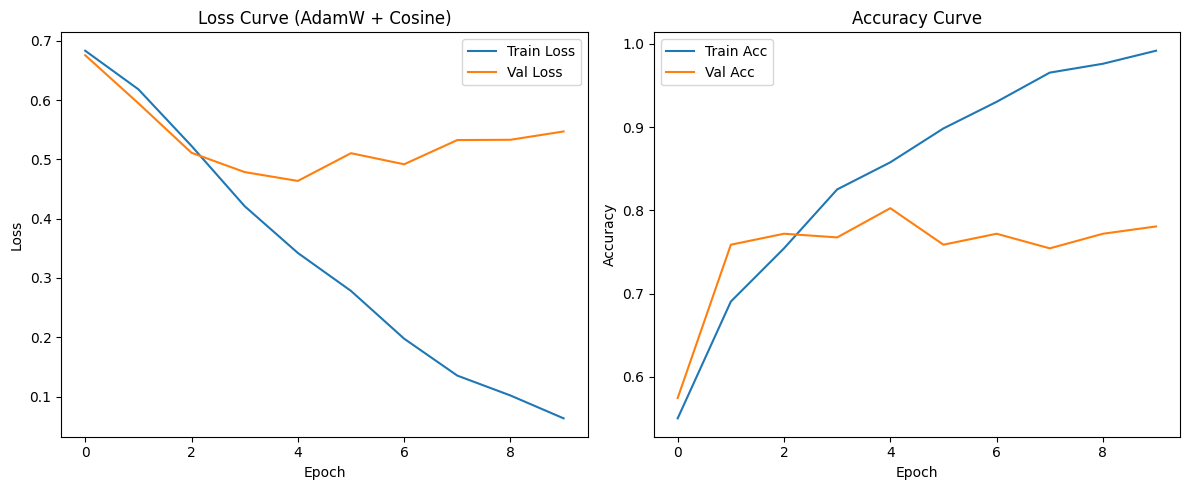

In [ ]:
!pip install -q datasets scikit-learn matplotlib
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import models, transforms
from datasets import load_dataset
from tqdm import tqdm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# --- 1. CONFIGURATION ---
DATASET_ID = "123ccls/POLCOVID_task2_70_10_20"
BATCH_SIZE = 32
LEARNING_RATE = 1e-5
NUM_EPOCHS = 20
PATIENCE = 5          # Stop if no improvement for 5 epochs
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Using device: {DEVICE}")

# --- 2. DATA PREPARATION ---
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def collate_fn(batch, transform_func):
    images = []
    labels = []
    for item in batch:
        # Crucial for X-rays: Ensure they are 3-channel RGB for ResNet
        img = item['image'].convert("RGB")
        images.append(transform_func(img))
        labels.append(item['label'])
    return torch.stack(images), torch.tensor(labels)

print("Loading dataset...")
dataset = load_dataset(DATASET_ID)

train_loader = DataLoader(dataset['train'], batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=lambda x: collate_fn(x, train_transforms))
val_loader   = DataLoader(dataset['validation'], batch_size=BATCH_SIZE, shuffle=False,
                          collate_fn=lambda x: collate_fn(x, test_transforms))
test_loader  = DataLoader(dataset['test'], batch_size=BATCH_SIZE, shuffle=False,
                          collate_fn=lambda x: collate_fn(x, test_transforms))

class_names = dataset['train'].features['label'].names
NUM_CLASSES = len(class_names)
print(f"Detected Classes: {class_names}")

# --- 3. MODEL SETUP ---
model = models.resnet50(weights='IMAGENET1K_V1')
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, NUM_CLASSES)
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()

# AdamW with Decoupled Weight Decay (Industry standard for medical imaging)
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE)

from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR

# 1. Warmup for 2 epochs (Protects pretrained weights from sudden shocks)
warmup_epochs = 2
warmup_scheduler = LinearLR(optimizer, start_factor=0.1, total_iters=warmup_epochs)

# 2. Cosine Annealing for the remaining epochs (Matches Gemma 3 exactly)
cosine_scheduler = CosineAnnealingLR(optimizer, T_max=(NUM_EPOCHS - warmup_epochs), eta_min=1e-7)

# 3. Combine into a Sequential Scheduler
scheduler = SequentialLR(optimizer, schedulers=[warmup_scheduler, cosine_scheduler], milestones=[warmup_epochs])

# --- 4. TRAINING & EVALUATION FUNCTIONS ---
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    running_loss, preds_all, labels_all = 0.0, [], []
    for images, labels in tqdm(loader, desc="Training"):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        preds_all.extend(preds.cpu().numpy())
        labels_all.extend(labels.cpu().numpy())
    return running_loss / len(loader.dataset), accuracy_score(labels_all, preds_all)

def evaluate(model, loader, criterion, desc="Validating"):
    model.eval()
    running_loss, preds_all, labels_all = 0.0, [], []
    with torch.no_grad():
        for images, labels in tqdm(loader, desc=desc):
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            preds_all.extend(preds.cpu().numpy())
            labels_all.extend(labels.cpu().numpy())
    return running_loss / len(loader.dataset), accuracy_score(labels_all, preds_all), preds_all, labels_all

# --- 5. MAIN EXECUTION WITH EARLY STOPPING ---
best_val_loss = float('inf')
patience_counter = 0
best_model_path = "resnet50_best.pth"
best_epoch = 0
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

print("\nStarting Training...")
for epoch in range(NUM_EPOCHS):
    print(f"\nEpoch {epoch+1}/{NUM_EPOCHS}")

    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion, desc="Validating")

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss:   {val_loss:.4f}  | Val Acc:   {val_acc:.4f}")

    # Trigger Learning Rate Update
    scheduler.step()
    current_lr = optimizer.param_groups[0]['lr']
    print(f"Current Learning Rate: {current_lr:.2e}")

    # EARLY STOPPING LOGIC
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        patience_counter = 0
        torch.save(model.state_dict(), best_model_path)
        print(f"--> New Best Validation Loss! Model Saved (Epoch {best_epoch}).")
    else:
        patience_counter += 1
        print(f"No improvement. Patience: {patience_counter}/{PATIENCE}")

    if patience_counter >= PATIENCE:
        print("--> Early Stopping Triggered!")
        break

print(f"\nTraining Complete. Best Model was from Epoch {best_epoch}.")

# --- 6. FINAL TEST (ON THE HELD-OUT TEST SET) ---
print("\nLoading Best Model for Final Testing...")
model.load_state_dict(torch.load(best_model_path, weights_only=True))
test_loss, test_acc, preds, labels = evaluate(model, test_loader, criterion, desc="Testing")

print(f"\nFINAL TEST ACCURACY: {test_acc:.2%}")
print("\nDetailed Classification Report:")
print(classification_report(labels, preds, target_names=class_names))

# --- 7. PLOT HISTORY ---
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Val Loss')
plt.title('Loss Curve (AdamW + Cosine)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='Train Acc')
plt.plot(history['val_acc'], label='Val Acc')
plt.title('Accuracy Curve')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()


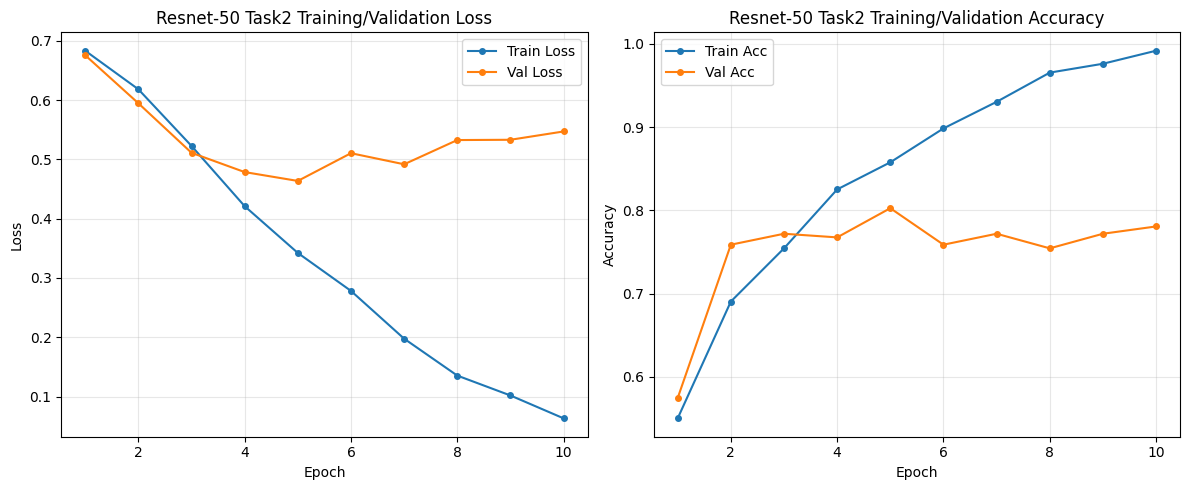

In [ ]:
# --- 7. PLOT HISTORY (Updated for FYP) ---

# Create an x-axis that starts at 1 instead of 0
epochs = range(1, len(history['train_loss']) + 1)

plt.figure(figsize=(12, 5))

# 1. Loss Curve
plt.subplot(1, 2, 1)
plt.plot(epochs, history['train_loss'], label='Train Loss', marker='o', markersize=4)
plt.plot(epochs, history['val_loss'], label='Val Loss', marker='o', markersize=4)
plt.title('Resnet-50 Task2 Training/Validation Loss')
plt.xlabel('Epoch')  # Added label
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3) # Added grid for better readability

# 2. Accuracy Curve
plt.subplot(1, 2, 2)
plt.plot(epochs, history['train_acc'], label='Train Acc', marker='o', markersize=4)
plt.plot(epochs, history['val_acc'], label='Val Acc', marker='o', markersize=4)
plt.title('Resnet-50 Task2 Training/Validation Accuracy')
plt.xlabel('Epoch')  # Added label
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



✅ Fine Tuned Resnet-50 Task2 Accuracy: 76.32%
🏥 Sensitivity: 78.07%
🛡️ Specificity:  74.56%

📊 Detailed Report:
                     precision    recall  f1-score   support

           COVID-19       0.75      0.78      0.77       228
Non-COVID Pneumonia       0.77      0.75      0.76       228

           accuracy                           0.76       456
          macro avg       0.76      0.76      0.76       456
       weighted avg       0.76      0.76      0.76       456



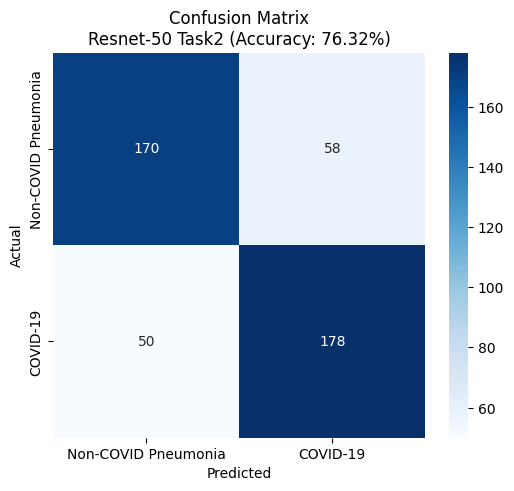

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# ==========================================
# 0. BRIDGE: Convert integers to string class names
# ==========================================
# Your testing loop output 'labels' and 'preds' as integers.
# We map them to their actual text names using 'class_names' from Block 1
y_true = [class_names[label] for label in labels]
y_pred = [class_names[pred] for pred in preds]

# NOTE: Make sure the strings below EXACTLY match the names in your `class_names` list!
# If your dataset uses different exact spelling (e.g., "Normal", "COVID", "Pneumonia"),
# you must change the text in the `labels=[...]` arrays below to match.
TARGET_CLASSES = ["Non-COVID Pneumonia", "COVID-19"]

# ==========================================
# CALCULATE METRICS & PLOT
# ==========================================

# 1. Calculate Accuracy (Overall)
acc = accuracy_score(y_true, y_pred)
accuracy_pct = acc * 100

# 2. Confusion Matrix (Restricted to the 2 target classes for the math below)
cm = confusion_matrix(y_true, y_pred, labels=TARGET_CLASSES)

# 3. Extract TN, FP, FN, TP
tn, fp, fn, tp = cm.ravel()

# 4. Calculate Sensitivity & Specificity
# Sensitivity = True Positive Rate (How well it finds COVID-19 / target)
sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0

# Specificity = True Negative Rate (How well it identifies the other class)
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

# 5. Print Text Reports
print(f"\n✅ Fine Tuned Resnet-50 Task2 Accuracy: {accuracy_pct:.2f}%")
print(f"🏥 Sensitivity: {sensitivity * 100:.2f}%")
print(f"🛡️ Specificity:  {specificity * 100:.2f}%")

print("\n📊 Detailed Report:")
print(classification_report(y_true, y_pred)) # Removed labels filter to show all 3 classes if present

# 6. Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=TARGET_CLASSES,
            yticklabels=TARGET_CLASSES)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f"Confusion Matrix\nResnet-50 Task2 (Accuracy: {accuracy_pct:.2f}%)")
plt.show()


In [ ]:
# ==========================================
# FINAL STEP: SAVE PREDICTIONS TO CSV
# ==========================================
import pandas as pd

# 1. Load the Best Model (Just to be sure)
model.load_state_dict(torch.load("resnet50_best.pth", weights_only=True))
model.eval()

print("Generating Final CSV...")
all_preds = []
all_labels = []

# 2. Run Inference Loop
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Saving CSV"):
        images = images.to(DEVICE)

        # Get Predictions
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        # Move to CPU and store
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# 3. Create DataFrame
# We map numbers back to names for readability
# 0 -> Normal, 1 -> Pneumonia (Check your specific dataset order if unsure)
label_map = {i: name for i, name in enumerate(class_names)}

df_results = pd.DataFrame({
    "Index": range(len(all_preds)),
    "True_Label_ID": all_labels,
    "Predicted_Label_ID": all_preds,
    "True_Label_Name": [label_map[i] for i in all_labels],
    "Predicted_Label_Name": [label_map[i] for i in all_preds]
})

# 4. Save to CSV

df = df_results
# Save predictions under Results/CNN/Task2/ with task + accuracy in filename
from pathlib import Path
import re

TASK_ID = "Task2_ResNet"
RESULTS_PROJECT_ROOT = Path(
    r"C:\Users\Henryayay\OneDrive - The Hong Kong Polytechnic University\Desktop\AI xray classification project\Results"
)
LOCAL_RESULTS_ROOT = RESULTS_PROJECT_ROOT / "CNN" / "Task2"

def _slug(text):
    text = str(text).strip().replace(" ", "-")
    return re.sub(r"[^A-Za-z0-9._-]+", "_", text)

filename = f"{_slug(TASK_ID)}_cnn_resnet50_acc{accuracy_pct:.2f}pct.csv"
dest_dir = None
for candidate in (LOCAL_RESULTS_ROOT, Path.cwd() / "Results" / "CNN" / "Task2"):
    try:
        candidate.mkdir(parents=True, exist_ok=True)
        probe = candidate / ".write_test"
        probe.write_text("ok", encoding="utf-8")
        probe.unlink()
        dest_dir = candidate
        break
    except Exception:
        continue
if dest_dir is None:
    dest_dir = Path.cwd() / "Results" / "CNN" / "Task2"
    dest_dir.mkdir(parents=True, exist_ok=True)
dest_path = dest_dir / filename
df.to_csv(dest_path, index=False)
print("Saved:", dest_path)
try:
    from google.colab import files
    if str(LOCAL_RESULTS_ROOT) not in str(dest_path):
        print(f"If the browser save dialog appears, choose:\n{LOCAL_RESULTS_ROOT}")
        files.download(str(dest_path))
except Exception as exc:
    print("Download skipped:", exc)


Generating Final CSV...


Saving CSV: 100%|██████████| 15/15 [00:06<00:00,  2.43it/s]

Success! Saved to resnet_predictions_task2.csv
   Index  True_Label_ID  Predicted_Label_ID      True_Label_Name  \
0      0              1                   1             COVID-19   
1      1              1                   1             COVID-19   
2      2              1                   1             COVID-19   
3      3              0                   0  Non-COVID Pneumonia   
4      4              0                   1  Non-COVID Pneumonia   

  Predicted_Label_Name  
0             COVID-19  
1             COVID-19  
2             COVID-19  
3  Non-COVID Pneumonia  
4             COVID-19  


In [ ]:
from IPython.display import FileLink, display
from pathlib import Path
candidates = sorted(Path('.').glob('Task2_ResNet_*_acc*.csv'), key=lambda p: p.stat().st_mtime, reverse=True)
if not candidates and 'LOCAL_RESULTS_ROOT' in globals():
    candidates = sorted(LOCAL_RESULTS_ROOT.glob('Task2_ResNet_*_acc*.csv'), key=lambda p: p.stat().st_mtime, reverse=True)
if candidates:
    display(FileLink(str(candidates[0])))
else:
    print('No Task2_ResNet_*_acc*.csv found yet. Run the evaluation/save cell first.')


/kaggle/working/resnet_predictions_task2.csv

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


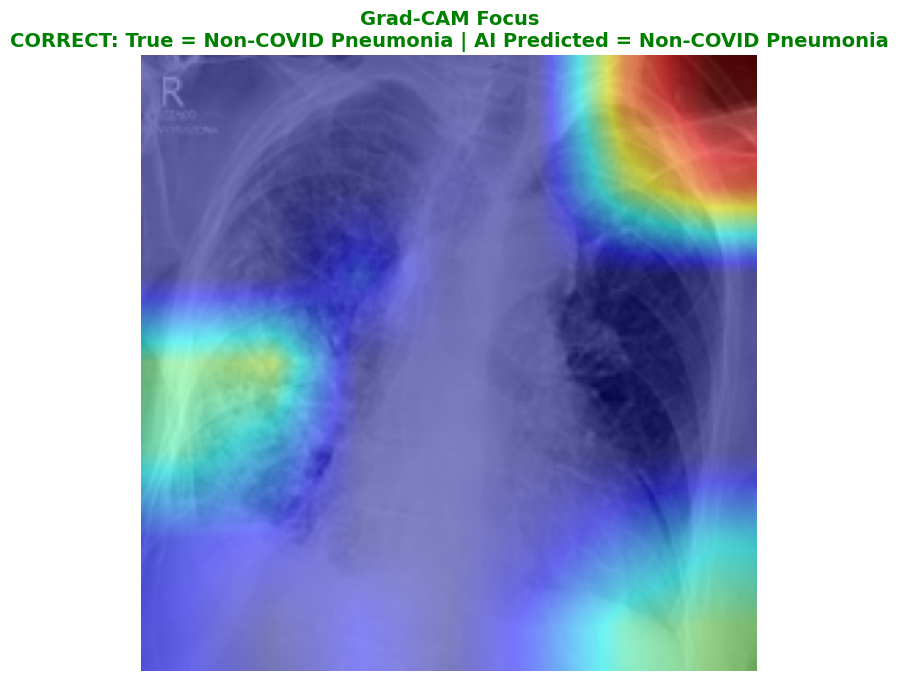

In [ ]:
# ==========================================
# GRAD-CAM VISUALIZATION (With Predictions)
# ==========================================
!pip install -q grad-cam

import numpy as np
import matplotlib.pyplot as plt
import torch
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from PIL import Image

# 1. SETUP MODEL
model.eval()
target_layers = [model.layer4[-1]] # Last ResNet layer

# 2. SELECT IMAGE
image_index = 5 # <--- Change this to test different images
image_pil = dataset['test'][image_index]['image'].convert("RGB")
true_label = dataset['test'][image_index]['label']

# Get actual class names from dataset (e.g., ['Normal', 'Pneumonia'])
class_names = dataset['train'].features['label'].names
true_name = class_names[true_label]

# 3. PREPROCESS & PREDICT
input_tensor = test_transforms(image_pil).unsqueeze(0).to(DEVICE)

# --- NEW: Get Model's Prediction ---
with torch.no_grad():
    outputs = model(input_tensor)
    _, predicted_class = torch.max(outputs, 1)
    predicted_label = predicted_class.item()
    pred_name = class_names[predicted_label]

# 4. RUN GRAD-CAM
cam = GradCAM(model=model, target_layers=target_layers)

# --- NEW: Ask Grad-CAM "Why did you make THIS specific prediction?" ---
targets = [ClassifierOutputTarget(predicted_label)]

grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
grayscale_cam = grayscale_cam[0, :]

# 5. VISUALIZE
# Prepare Background Image
rgb_img = np.array(image_pil.resize((224, 224)))
rgb_img = np.float32(rgb_img) / 255.0

# Overlay
visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

# 6. PLOT
# Make the title Green if correct, Red if wrong
title_color = "green" if true_label == predicted_label else "red"
result_text = "CORRECT" if true_label == predicted_label else "WRONG"

plt.figure(figsize=(8, 8))
plt.imshow(visualization)
plt.title(f"Grad-CAM Focus\n{result_text}: True = {true_name} | AI Predicted = {pred_name}",
          color=title_color, fontsize=14, fontweight='bold')
plt.axis("off")
plt.show()


In [ ]:


# --- 1. CONFIGURATION ---
DATASET_ID = "123ccls/POLCOVID_task2_70_10_20"
BATCH_SIZE = 32
LEARNING_RATE = 1e-4
NUM_EPOCHS = 30
PATIENCE = 5          # Stop if no improvement for 5 epochs
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Using device: {DEVICE}")

# --- 2. DATA PREPARATION ---
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def collate_fn(batch, transform_func):
    images = []
    labels = []
    for item in batch:
        # Crucial for X-rays: Ensure they are 3-channel RGB for ResNet
        img = item['image'].convert("RGB")
        images.append(transform_func(img))
        labels.append(item['label'])
    return torch.stack(images), torch.tensor(labels)

print("Loading dataset...")
dataset = load_dataset(DATASET_ID)

train_loader = DataLoader(dataset['train'], batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=lambda x: collate_fn(x, train_transforms))
val_loader   = DataLoader(dataset['validation'], batch_size=BATCH_SIZE, shuffle=False,
                          collate_fn=lambda x: collate_fn(x, test_transforms))
test_loader  = DataLoader(dataset['test'], batch_size=BATCH_SIZE, shuffle=False,
                          collate_fn=lambda x: collate_fn(x, test_transforms))

class_names = dataset['train'].features['label'].names
NUM_CLASSES = len(class_names)
print(f"Detected Classes: {class_names}")

# --- 3. MODEL SETUP ---
model = models.resnet50(weights='IMAGENET1K_V1')
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, NUM_CLASSES)
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()

# AdamW with Decoupled Weight Decay (Industry standard for medical imaging)
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE)

from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR

# 1. Warmup for 5 epochs (Protects pretrained weights from sudden shocks)
warmup_epochs = 3
warmup_scheduler = LinearLR(optimizer, start_factor=0.1, total_iters=warmup_epochs)

# 2. Cosine Annealing for the remaining epochs (Matches Gemma 3 exactly)
cosine_scheduler = CosineAnnealingLR(optimizer, T_max=(NUM_EPOCHS - warmup_epochs), eta_min=1e-7)

# 3. Combine into a Sequential Scheduler
scheduler = SequentialLR(optimizer, schedulers=[warmup_scheduler, cosine_scheduler], milestones=[warmup_epochs])

# --- 4. TRAINING & EVALUATION FUNCTIONS ---
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    running_loss, preds_all, labels_all = 0.0, [], []
    for images, labels in tqdm(loader, desc="Training"):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        preds_all.extend(preds.cpu().numpy())
        labels_all.extend(labels.cpu().numpy())
    return running_loss / len(loader.dataset), accuracy_score(labels_all, preds_all)

def evaluate(model, loader, criterion, desc="Validating"):
    model.eval()
    running_loss, preds_all, labels_all = 0.0, [], []
    with torch.no_grad():
        for images, labels in tqdm(loader, desc=desc):
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            preds_all.extend(preds.cpu().numpy())
            labels_all.extend(labels.cpu().numpy())
    return running_loss / len(loader.dataset), accuracy_score(labels_all, preds_all), preds_all, labels_all

# --- 5. MAIN EXECUTION WITH EARLY STOPPING ---
best_val_loss = float('inf')
patience_counter = 0
best_model_path = "resnet50_best.pth"
best_epoch = 0
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

print("\nStarting Training...")
for epoch in range(NUM_EPOCHS):
    print(f"\nEpoch {epoch+1}/{NUM_EPOCHS}")

    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion, desc="Validating")

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss:   {val_loss:.4f}  | Val Acc:   {val_acc:.4f}")

    # Trigger Learning Rate Update
    scheduler.step()
    current_lr = optimizer.param_groups[0]['lr']
    print(f"Current Learning Rate: {current_lr:.2e}")

    # EARLY STOPPING LOGIC
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        patience_counter = 0
        torch.save(model.state_dict(), best_model_path)
        print(f"--> New Best Validation Loss! Model Saved (Epoch {best_epoch}).")
    else:
        patience_counter += 1
        print(f"No improvement. Patience: {patience_counter}/{PATIENCE}")

    if patience_counter >= PATIENCE:
        print("--> Early Stopping Triggered!")
        break

print(f"\nTraining Complete. Best Model was from Epoch {best_epoch}.")

# --- 6. FINAL TEST (ON THE HELD-OUT TEST SET) ---
print("\nLoading Best Model for Final Testing...")
model.load_state_dict(torch.load(best_model_path, weights_only=True))
test_loss, test_acc, preds, labels = evaluate(model, test_loader, criterion, desc="Testing")

print(f"\nFINAL TEST ACCURACY: {test_acc:.2%}")
print("\nDetailed Classification Report:")
print(classification_report(labels, preds, target_names=class_names))

# --- 7. PLOT HISTORY ---
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Val Loss')
plt.title('Loss Curve (AdamW + Cosine)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='Train Acc')
plt.plot(history['val_acc'], label='Val Acc')
plt.title('Accuracy Curve')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()


Using device: cuda
Loading dataset...
Detected Classes: ['Non-COVID Pneumonia', 'COVID-19']

Starting Training...

Epoch 1/30


Validating: 100%|██████████| 8/8 [00:03<00:00,  2.58it/s]


Train Loss: 0.6402 | Train Acc: 0.6203
Val Loss:   0.5711  | Val Acc:   0.7544
Current Learning Rate: 4.00e-05
--> New Best Validation Loss! Model Saved (Epoch 1).

Epoch 2/30


Training:  98%|█████████▊| 49/50 [00:34<00:00,  1.43it/s]